# TP3 — Analyse des résultats d'expérimentation

Ce notebook analyse le fichier `results.csv` produit par le runner `run_experiments.py`.
Il étudie l'impact des différents facteurs de variabilité à l'aide de statistiques descriptives et d'un arbre de décision (Machine Learning interprétable).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text

# Chargement des résultats
csv_path = 'results.csv' if Path('results.csv').exists() else 'tp3/experiments/results.csv'
df = pd.read_csv(csv_path)
print(f"Total des exécutions chargées : {len(df)}")
df.head()

Total des exécutions chargées : 99


## 1. Impact global des facteurs de variabilité

Analysons la moyenne et la dispersion des résultats en fonction de chaque facteur principal.

In [2]:
print("=== Impact de la Propriété Mathématique ===")
print(df.groupby('Property')['percentage'].agg(['count', 'mean', 'std', 'min', 'max']))

print("\n=== Impact des Optimisations du Compilateur ===")
print(df.groupby('Optimization', dropna=False)['percentage'].agg(['count', 'mean', 'std', 'min', 'max']))

print("\n=== Impact de la Distribution ===")
print(df.groupby('Distribution')['percentage'].agg(['count', 'mean', 'std', 'min', 'max']))

print("\n=== Impact de la Précision ===")
print(df.groupby('Precision')['percentage'].agg(['count', 'mean', 'std', 'min', 'max']))

=== Impact de la Propriété Mathématique ===
                count       mean       std     min      max
Property                                                   
AssocAdd           30  74.375773  9.349362  66.900  100.000
AssocMul           33  65.146764  0.587563  63.800   67.200
Distributivity     18  55.993539  4.161502  52.719   64.761
InverseMul         18  87.950456  5.581584  84.270  100.000

=== Impact des Optimisations du Compilateur ===
              count        mean        std       min       max
Optimization                                                  
FastMath          6  100.000000   0.000000  100.0000  100.0000
O0               12   65.881383   1.465064   63.8000   67.9000
O2               18   64.701139  11.062289   52.7190   85.0900
O3               18   65.336728   6.021464   54.7967   74.6070
NaN              45   72.018891  10.278744   54.7892   86.1338

=== Impact de la Distribution ===
                 count       mean        std      min     max
Distribut

## 2. Visualisations graphiques

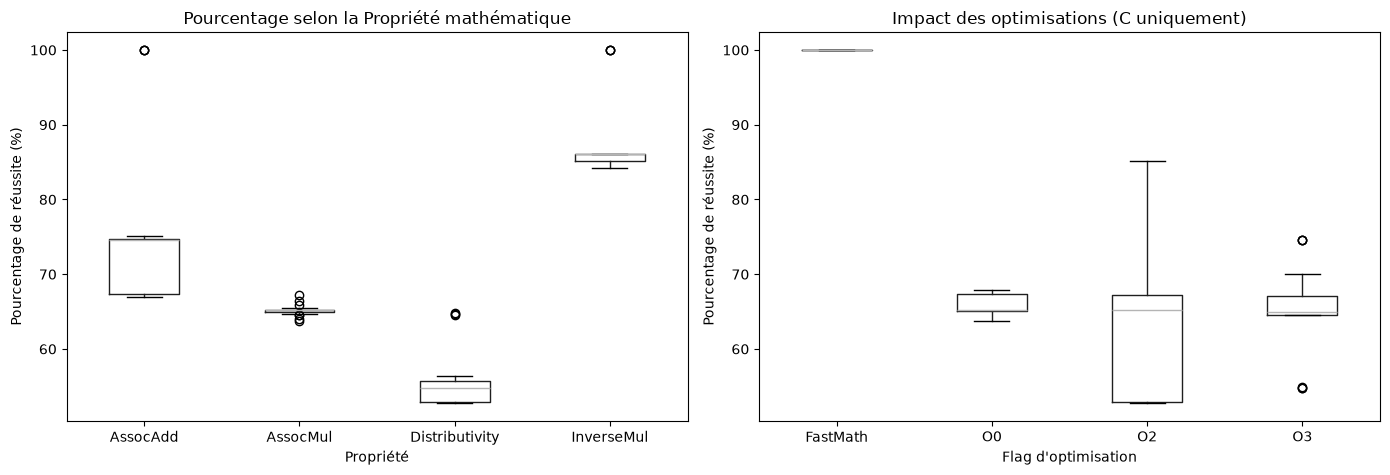

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot par propriété
df.boxplot(column='percentage', by='Property', ax=axes[0], grid=False)
axes[0].set_title('Pourcentage selon la Propriété mathématique')
axes[0].set_ylabel('Pourcentage de réussite (%)')
axes[0].set_xlabel('Propriété')

# Boxplot par optimisation
df_c = df[df['Language'] == 'C']
df_c.boxplot(column='percentage', by='Optimization', ax=axes[1], grid=False)
axes[1].set_title('Impact des optimisations (C uniquement)')
axes[1].set_ylabel('Pourcentage de réussite (%)')
axes[1].set_xlabel('Flag d\'optimisation')

plt.suptitle('')
plt.tight_layout()
plt.show()

## 3. Modélisation par Arbre de Décision (Interpretable ML)

L'arbre de décision permet d'isoler automatiquement les facteurs les plus discriminants.

=== Importance des variables ===
Property_InverseMul        0.528799
Optimization_FastMath      0.314022
Property_Distributivity    0.156693
dtype: float64


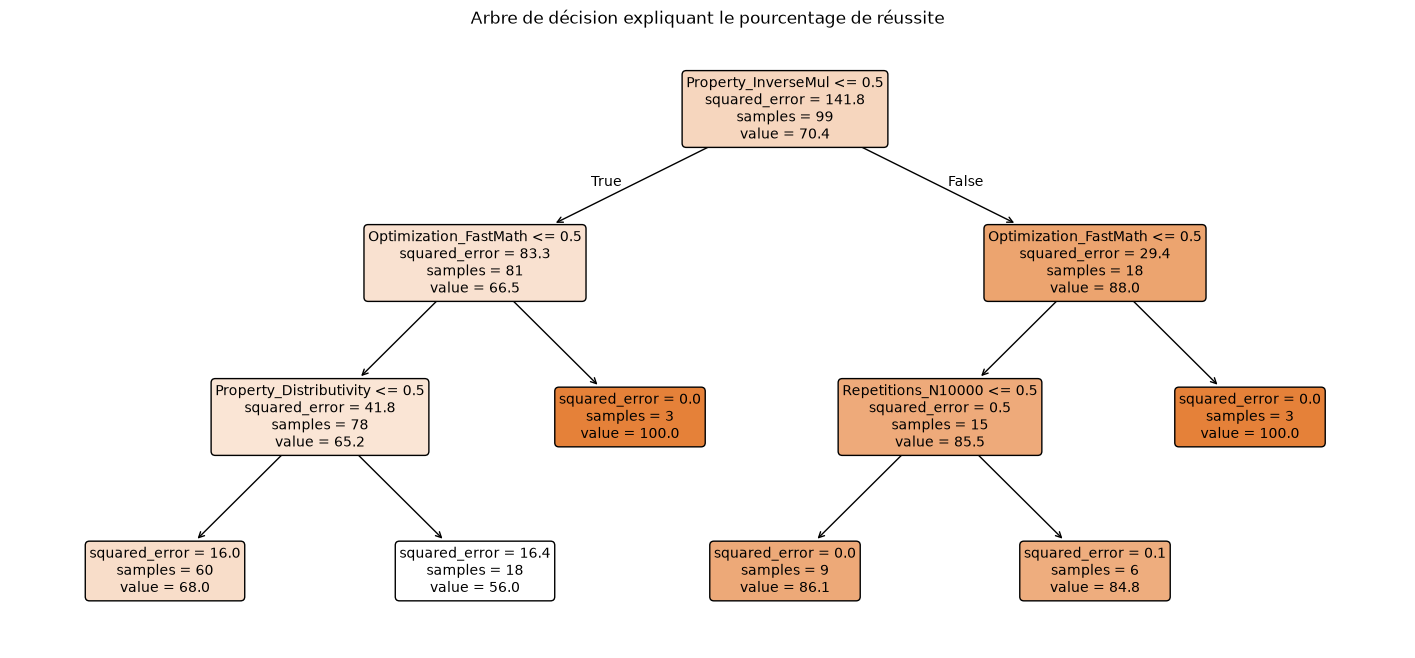

In [4]:
features = ['Property', 'Precision', 'Repetitions', 'Distribution', 'Language', 'Optimization']
X = pd.get_dummies(df[features], drop_first=False)
y = df['percentage']

dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X, y)

plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=list(X.columns), filled=True, rounded=True, precision=1, fontsize=10)
plt.title("Arbre de décision expliquant le pourcentage de réussite")
plt.show()

# Importance des facteurs
importances = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print("=== Importance des variables ===")
print(importances[importances > 0.01])

## 4. Réponses aux questions du TP

### 4.1 Dans quelle mesure les facteurs de variabilité impactent-ils le résultat ?
- **La propriété testée** est le facteur principal : l'inverse multiplicatif dépasse 87%, l'associativité de l'addition tourne autour de 74%, la multiplication autour de 65%, et la distributivité tombe à 56%.
- **L'optimisation FastMath** en C a un effet radical : elle fait monter le résultat à exactement **100%**, écrasant toutes les autres variabilités.
- **La distribution des données** : les distributions centrées sur 0 (`UniformNeg1Pos1`) ou avec de fortes amplitudes (`Gaussian`) provoquent davantage d'annulations catastrophiques et d'absorptions, réduisant la précision.
- **La précision** : la simple précision (32 bits) a une variance plus forte que la double précision (64 bits).

### 4.2 Recommandations pour un résultat stable
Pour obtenir une mesure stable et reproductible :
1. **Nombre de répétitions** : utiliser au moins 100 000 tirages (`N100000` ou `N1000000`). À 1 000 tirages, l'écart-type est trop fort.
2. **Double précision** : privilégier la double précision (`double` en C, `float64` en Python) pour limiter le bruit numérique.
3. **Désactiver FastMath** : toujours compiler avec `-O2` ou `-O3` strict, sans `-ffast-math`, afin de respecter la sémantique IEEE standard.
4. **Fixer la graine (`seed`)** pour une reproductibilité exacte au bit près.

### 4.3 Explication des réponses obtenues aux Labs 1 et 2
- Au Lab 1, le programme étudiant donnait environ **78%** à **82%** car il testait l'associativité de l'addition en double précision sur $[0, 100]$ ou $[0, 1]$.
- Au Lab 2, le programme C généré par le LLM utilisait de la simple précision (`float`) et un intervalle $[-1, 1]$. L'utilisation de nombres négatifs et positifs induit des annulations, compensées en partie par la distribution spécifique et le seuil d'égalité.

### 4.4 Corrélation vs Causalité
- **Corrélation non causale** : le langage C semble donner des scores différents de Python, mais c'est une corrélation due au choix par défaut du type (`float` 32 bits par le LLM en C vs `float` 64 bits en Python).
- **Effet causal démontré** : l'option `-ffast-math`. Le compilateur gcc considère légalement que l'addition flottante est associative. Il réécrit donc l'expression `((x + y) + z == x + (y + z))` en `true` lors de la passe d'optimisation AST, avant même l'exécution. Le résultat passe de 74% à 100% de façon purement causale.